# Animal Image Classification with CNN

This project uses a Convolutional Neural Network (CNN) to classify animal images. The dataset is loaded from Hugging Face, and the images are preprocessed before being used to train and evaluate the model.

The goal is to practice image preprocessing, CNN architecture design, and model evaluation using TensorFlow and Keras.

In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from datasets import load_dataset

## 2. Load Dataset

In this section, we load the Beans dataset from Hugging Face and separate it into training, validation, and test sets.

In [ ]:
# Load the animal image dataset
animals = load_dataset("Melisa13/Animals_dataset")

# Select the training and test splits
train = animals["train"]
test = animals["test"]

# Display the dataset structure
print(animals)

train/cats/cats_00062.jpg: reconstructing file:   0%|          |  0.00B / 14.5kB            

train/cats/cats_00063.jpg: reconstructing file:   0%|          |  0.00B / 18.2kB            

train/cats/cats_00064.jpg: reconstructing file:   0%|          |  0.00B / 8.07kB            

train/cats/cats_00065.jpg: reconstructing file:   0%|          |  0.00B / 26.6kB            

train/cats/cats_00071.jpg: reconstructing file:   0%|          |  0.00B / 5.94kB            

...

test/panda/panda_00183.jpg: downloading bytes:           |  0.00B            

test/panda/panda_00178.jpg: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/480 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/120 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 480
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 120
    })
})


In [ ]:
# Select the training and test datasets
train= animals['train']
test= animals['test']

\## 3. Exploratory Data Analysis (EDA)

In [93]:

# Display the number of samples in each split
print("Training samples:", len(train))
print("Test samples:", len(test))

# Display the available animal classes
print("Classes:", train.features["label"].names)

# Display the size of the first image
print("Image size:", train[0]["image"].size)

Training samples: 480
Test samples: 120
['cats', 'dogs', 'panda']
(500, 374)


## 4. Inspect a Sample

In [94]:
# Select one sample from the training set
sample0 = train[0]
sample1 = test[0]

# Display the sample's keys
print(sample0.keys())

# Display the image size and label in train dataset
print("Train Image size:", sample0["image"].size)
print("Train Label:", sample0["label"])


# Display the image size and label in test dataset
print("Test Image size:", sample1["image"].size)
print("Test Label:", sample1["label"])

dict_keys(['image', 'label'])
Train Image size: (500, 374)
Train Label: 0
Test Image size: (500, 438)
Test Label: 0


## 5. Visualize a Sample Image

In this section, we visualize a bean leaf image and display its corresponding class label.

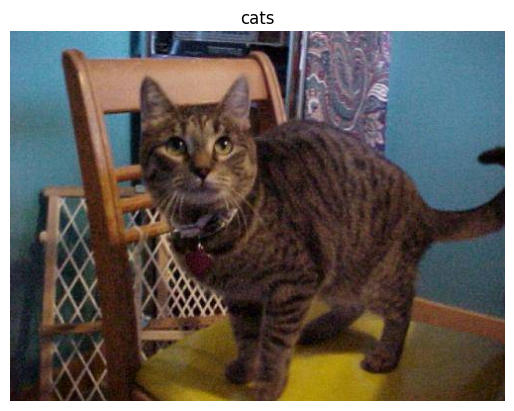

In [95]:
import matplotlib.pyplot as plt

# Select one sample from the training set
sample = train[0]

# Display the image
plt.imshow(sample["image"])
plt.title(train.features["label"].names[sample["label"]])
plt.axis("off")
plt.show()

## 6. Image Preprocessing

In this section, we resize the images to a fixed size and normalize pixel values to the range [0, 1]. This makes the images suitable for training the neural network.

In [96]:

# Check the minimum and maximum pixel values of the first five images
for i in range(5):
    sample = np.array(train[i]["image"])

    print(
        f"Image {i}:",
        "Min =", sample.min(),
        "Max =", sample.max()
    )


0 249
0 247
4 255
0 251
0 209


In [125]:
def preprocess_image(image):
    # Convert the image to RGB (3 color channels)
    image = image.convert("RGB")

    # Convert the image to a NumPy array
    image = np.array(image)

    # Resize the image to 128x128 pixels
    image = tf.image.resize(image, (128, 128))

    # Normalize pixel values to the range [0, 1]
    image = image / 255.0

    return image


In [ ]:

# Preprocess training images
x_train = np.array([
    preprocess_image(train[i]["image"])
    for i in range(len(train))
])

# Preprocess test images
x_test = np.array([
    preprocess_image(test[i]["image"])
    for i in range(len(test))
])


## 7. Build the CNN Model

In [137]:
model = keras.Sequential([
    keras.layers.Input(shape=(128, 128, 3)),

    keras.layers.Conv2D(32, (3, 3), activation="relu"),
    keras.layers.MaxPooling2D((2, 2)),

    keras.layers.Conv2D(64, (3, 3), activation="relu"),
    keras.layers.MaxPooling2D((2, 2)),

    keras.layers.Conv2D(128, (3, 3), activation="relu"),
    keras.layers.MaxPooling2D((2, 2)),

    keras.layers.Flatten(),

    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dense(3, activation="softmax")
])

## 8. Compile the Model

In this section, we configure the optimizer, loss function, and evaluation metric before training the CNN.

In [138]:
model.compile(optimizer = tf.optimizers.Adam() ,loss='sparse_categorical_crossentropy', metrics=['accuracy'] )



In [139]:
hist = model.fit(x_train, y_train, epochs=20, batch_size=32, validation_split=0.1)

Epoch 1/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 11s 583ms/step - accuracy: 0.3704 - loss: 1.2994 - val_accuracy: 0.0417 - val_loss: 1.1906
Epoch 2/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 8s 598ms/step - accuracy: 0.4815 - loss: 0.9902 - val_accuracy: 0.3750 - val_loss: 1.3913
Epoch 3/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 8s 591ms/step - accuracy: 0.5556 - loss: 0.8418 - val_accuracy: 0.5833 - val_loss: 0.8439
Epoch 4/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 10s 560ms/step - accuracy: 0.6319 - loss: 0.7414 - val_accuracy: 0.5833 - val_loss: 1.0574
Epoch 5/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 8s 558ms/step - accuracy: 0.6458 - loss: 0.6712 - val_accuracy: 0.4583 - val_loss: 1.1351
Epoch 6/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 10s 591ms/step - accuracy: 0.7407 - loss: 0.5642 - val_accuracy: 0.6250 - val_loss: 0.8841
Epoch 7/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 8s 594ms/step - accuracy: 0.7477 - loss: 0.5260 - val_accuracy: 0.6042 - val_loss: 1.1566
Epoch 8/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 8s 554ms/step - accuracy: 0.7569 - loss: 0.5248 - val_accuracy:

In [140]:
test_loss, test_accuracy = model.evaluate( x_test,y_test, verbose=1)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 207ms/step - accuracy: 0.5417 - loss: 2.0533
Test Loss: 2.0532572269439697
Test Accuracy: 0.5416666865348816


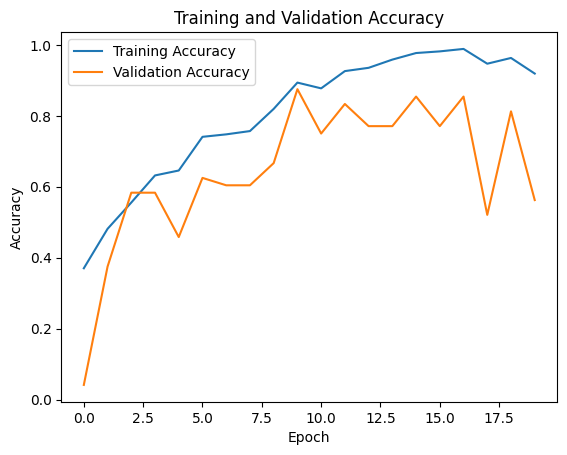

In [141]:
import matplotlib.pyplot as plt

plt.plot(hist.history["accuracy"], label="Training Accuracy")
plt.plot(hist.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.show()

In [136]:
print("Final training accuracy:", hist.history["accuracy"][-1])
print("Final validation accuracy:", hist.history["val_accuracy"][-1])

Final training accuracy: 0.5925925970077515
Final validation accuracy: 0.5
